# ClockMesh — mixed-sensor common timeline

**Test:** `20261113T090201.490293Z_cb1724e8` · three rigidly mounted Movella DOTs (60 Hz each) + one chest-worn Movesense ECG (200 Hz) · four independent ClockMesh models, one gateway reference clock.

**Purpose:** verify that samples from all four streams are represented on a **single gateway-reference timeline** and examine the difference between source measurement time, accepted mapped time and the gateway callback time.

This notebook shows:

- three DOT angular-velocity magnitude traces alongside Movesense ECG, using only *mapped measurement times* on the x-axis;
- a configurable zoom and acceleration comparison;
- all four mappings, accepted clock scales and callback prediction errors;
- pairwise rigid-mount motion agreement without shifting or optimising the signals;
- one identified ECG mapping discontinuity at the *startup → official* full-affine acceptance boundary (separate from the continuous official tracking phase).

**Important:** the ECG is on the chest; it is **not** physically rigid with the three DOTs. Its waveform is therefore plotted on the same time axis, but **not correlated with their gyroscope signals**. DOT-to-DOT agreement is a relative test, not an independent absolute timing reference.

## 1. Load capture and configure plots

Start Jupyter within the `nexus-n3-ble-tooling` repository (or a subdirectory). The notebook finds `output-files/clock-mesh-ecg/<capture-id>/` automatically. Leave `ZOOM_SECONDS = None` to centre the close-up on the largest official DOT rotation, or supply an explicit interval on the gateway-relative mapped timeline, for example `(14.0, 17.0)`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CAPTURE_ID = "20261113T090201.490293Z_cb1724e8"
CAPTURE_DIR_OVERRIDE = None  # Optionally set an explicit directory; normally leave as None.


def find_capture_dir(capture_id, override=None):
    if override is not None:
        folder = Path(override).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError(f"Capture override does not exist: {folder}")
        return folder
    cwd = Path.cwd().resolve()
    for base in (cwd, *cwd.parents):
        folder = base / "output-files" / "clock-mesh-ecg" / capture_id
        if folder.is_dir():
            return folder
    raise FileNotFoundError(
        f"Cannot find capture {capture_id!r} below the current working directory. "
        "Start Jupyter from nexus-n3-ble-tooling (or a subdirectory), "
        "or set CAPTURE_DIR_OVERRIDE above."
    )

capture_dir = find_capture_dir(CAPTURE_ID, CAPTURE_DIR_OVERRIDE)
print("Reading capture:", CAPTURE_ID)

plt.rcParams.update({
    "figure.dpi": 115,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.constrained_layout.use": True,
})

ZOOM_SECONDS = None       # (start, end) in seconds on the common mapped timeline
ZOOM_HALF_WIDTH_S = 1.25 # used only when ZOOM_SECONDS is None
SHOW_COMPONENTS = True   # extra DOT XYZ gyro and acceleration panels

Reading capture: 20261113T090201.490293Z_cb1724e8


In [2]:
with (capture_dir / "manifest.json").open(encoding="utf-8") as fh:
    manifest = json.load(fh)
with (capture_dir / "summary.json").open(encoding="utf-8") as fh:
    summary = json.load(fh)
with (capture_dir / "mapping_updates.json").open(encoding="utf-8") as fh:
    mapping_log = json.load(fh)

dots = pd.read_csv(capture_dir / "observations.csv")
ecg_packets = pd.read_csv(capture_dir / "ecg_packets.csv")
ecg_samples = pd.read_csv(capture_dir / "ecg_samples.csv")
assert dots["sensor_id"].nunique() == 3 and ecg_packets["sensor_id"].nunique() == 1
assert ecg_samples["packet_index"].nunique() == len(ecg_packets)

# Use ONE gateway-reference origin; never zero each sensor independently.
reference_origin_ns = min(int(dots["reference_time_ns"].min()), int(ecg_packets["reference_time_ns"].min()))
def seconds_from_gateway_origin(ns):
    return (pd.to_numeric(ns, errors="coerce") - reference_origin_ns) / 1e9

dot_official = dots[(dots["stream_phase"] == "measurement") & dots["mapped_timestamp_ns"].notna()].copy()
ecg_official = ecg_samples[(ecg_samples["stream_phase"] == "measurement") & ecg_samples["mapped_timestamp_ns"].notna()].copy()
pkt_official = ecg_packets[(ecg_packets["stream_phase"] == "measurement") & ecg_packets["mapped_timestamp_ns"].notna()].copy()

for frame in (dots, ecg_packets, ecg_samples, dot_official, ecg_official, pkt_official):
    frame["t_mapped_s"] = seconds_from_gateway_origin(frame["mapped_timestamp_ns"])
for frame in (dots, ecg_packets, dot_official, pkt_official):
    frame["t_callback_s"] = seconds_from_gateway_origin(frame["reference_time_ns"])

dot_official["gyro_mag_deg_s"] = np.linalg.norm(dot_official[["gyro_x_deg_s", "gyro_y_deg_s", "gyro_z_deg_s"]].to_numpy(float), axis=1)
dot_official["accel_mag_m_s2"] = np.linalg.norm(dot_official[["accel_x_m_s2", "accel_y_m_s2", "accel_z_m_s2"]].to_numpy(float), axis=1)

ecg_official.sort_values("t_mapped_s", inplace=True)
print("Capture:", CAPTURE_ID)
print(f"Official start (host elapsed): {summary['official_start']['host_elapsed_seconds']:.6f} s")
print(f"DOT official rows: {len(dot_official):,}; ECG packet timing observations: {len(pkt_official):,}; ECG samples: {len(ecg_official):,}")
print(f"Reference origin (gateway monotonic): {reference_origin_ns} ns")

Capture: 20261113T090201.490293Z_cb1724e8
Official start (host elapsed): 5.767883 s
DOT official rows: 4,362; ECG packet timing observations: 303; ECG samples: 4,848
Reference origin (gateway monotonic): 3972237760000 ns


## 2. Shared official-measurement overview

Both axes use exactly the same `t_mapped_s`, computed from `mapped_timestamp_ns` after subtracting a **single common gateway-reference origin**. No per-sensor shifting, peak matching or cross-correlation correction is applied. Gyroscope magnitude is orientation independent, making it suitable for the three rigidly mounted DOTs.

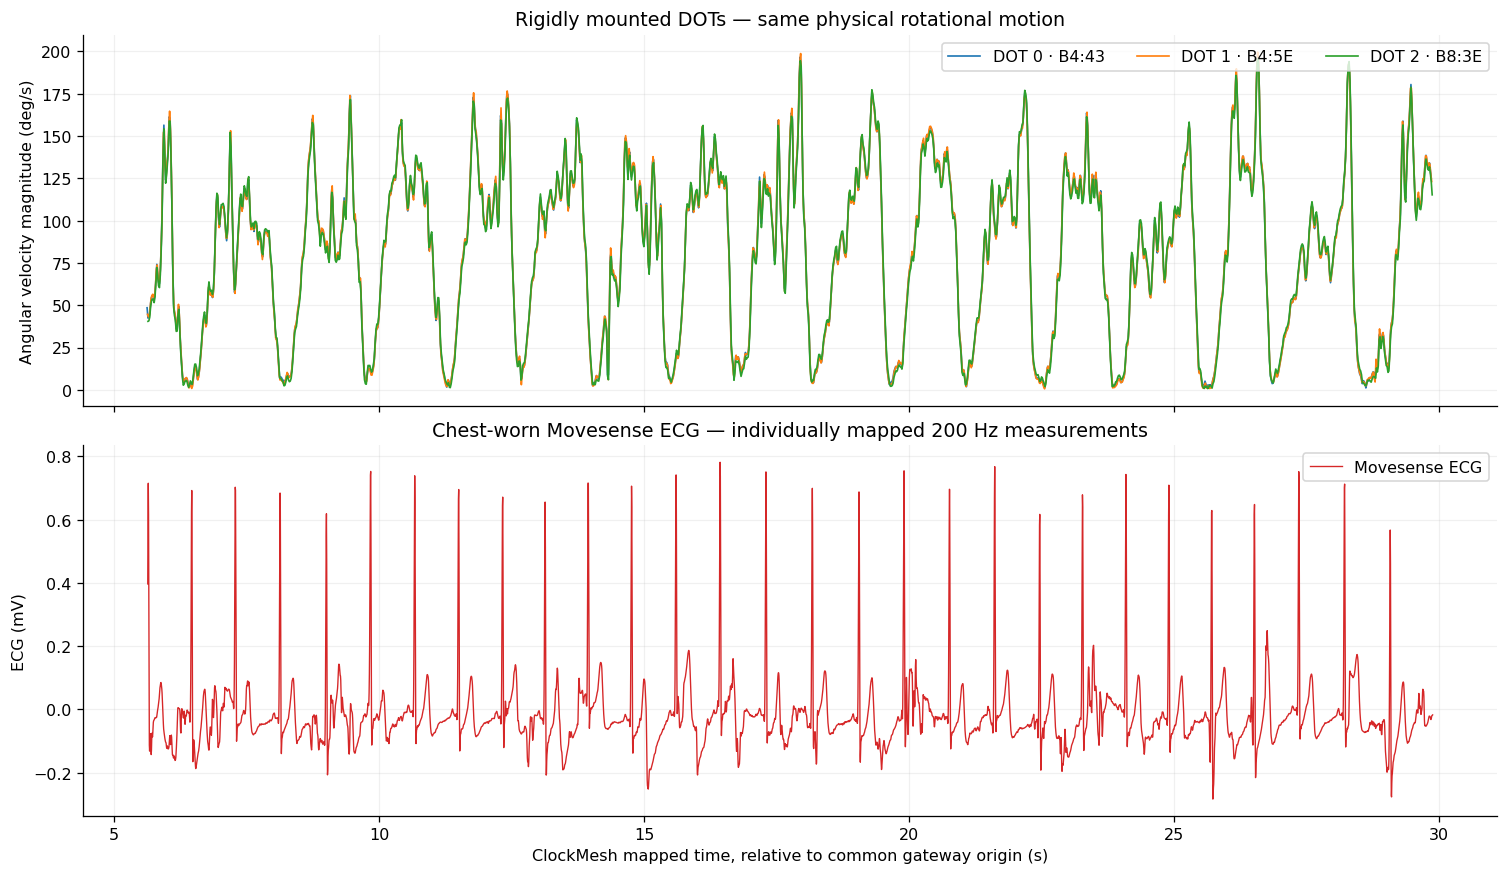

In [3]:
colors = plt.get_cmap("tab10")
fig, (ax_gyro, ax_ecg) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True,
                                     gridspec_kw={"height_ratios": [1, 1]})
for sid, g in dot_official.groupby("sensor_id", sort=True):
    g = g.sort_values("t_mapped_s")
    ax_gyro.plot(g["t_mapped_s"], g["gyro_mag_deg_s"], lw=1.05, label=f"DOT {sid} · {g['address'].iloc[0][-5:]}", color=colors(sid))
ax_gyro.set(ylabel="Angular velocity magnitude (deg/s)", title="Rigidly mounted DOTs — same physical rotational motion")
ax_gyro.legend(loc="upper right", ncol=3)
ax_ecg.plot(ecg_official["t_mapped_s"], ecg_official["ecg_mv"], color=colors(3), lw=.85, label="Movesense ECG")
ax_ecg.set(xlabel="ClockMesh mapped time, relative to common gateway origin (s)", ylabel="ECG (mV)",
           title="Chest-worn Movesense ECG — individually mapped 200 Hz measurements")
ax_ecg.legend(loc="upper right")
plt.show()

## 3. Close-up of the common timeline

By default the zoom selects the highest DOT 0 gyroscope-magnitude peak in the official recording, with ±1.25 seconds around it. Change `ZOOM_SECONDS` in the first cell to inspect any interval manually. The horizontal axis remains the *same mapped timeline* for both sensor types.

Zoom on mapped timeline: 25.332–27.832 s


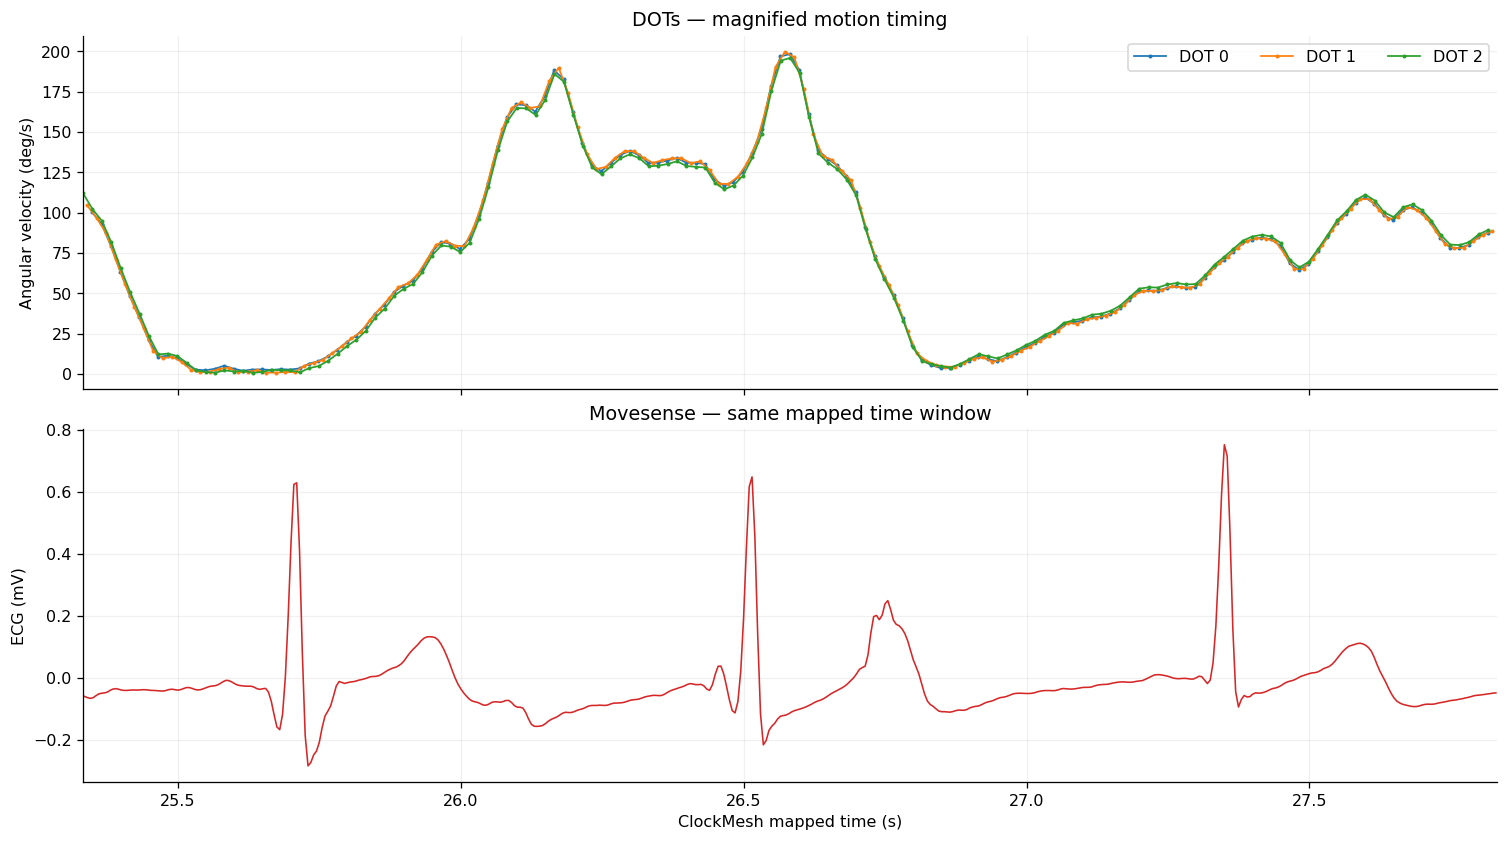

In [4]:
if ZOOM_SECONDS is None:
    reference_dot = dot_official.loc[dot_official["sensor_id"].eq(dot_official["sensor_id"].min())]
    strongest_peak = reference_dot.loc[reference_dot["gyro_mag_deg_s"].idxmax(), "t_mapped_s"]
    zoom = (float(strongest_peak) - ZOOM_HALF_WIDTH_S, float(strongest_peak) + ZOOM_HALF_WIDTH_S)
else:
    zoom = tuple(float(z) for z in ZOOM_SECONDS)
assert zoom[1] > zoom[0]
print(f"Zoom on mapped timeline: {zoom[0]:.3f}–{zoom[1]:.3f} s")

fig, (ax_gyro, ax_ecg) = plt.subplots(2, 1, figsize=(13, 7.2), sharex=True)
for sid, g in dot_official.groupby("sensor_id", sort=True):
    part = g[g["t_mapped_s"].between(*zoom)]
    ax_gyro.plot(part["t_mapped_s"], part["gyro_mag_deg_s"], marker=".", ms=3, lw=1.1, label=f"DOT {sid}", color=colors(sid))
part = ecg_official[ecg_official["t_mapped_s"].between(*zoom)]
ax_ecg.plot(part["t_mapped_s"], part["ecg_mv"], lw=1.0, color=colors(3))
ax_gyro.set(ylabel="Angular velocity (deg/s)", title="DOTs — magnified motion timing")
ax_ecg.set(xlabel="ClockMesh mapped time (s)", ylabel="ECG (mV)", title="Movesense — same mapped time window")
ax_gyro.legend(ncol=3)
ax_gyro.set_xlim(*zoom)
plt.show()

## 4. Acceleration magnitude relative to each DOT's stationary baseline

This is a descriptive motion comparison, not an extra alignment procedure. Each DOT's acceleration vector magnitude is expressed relative to its own median over the first second of official measurement, removing a constant gravity/mounting offset without altering the time axis.

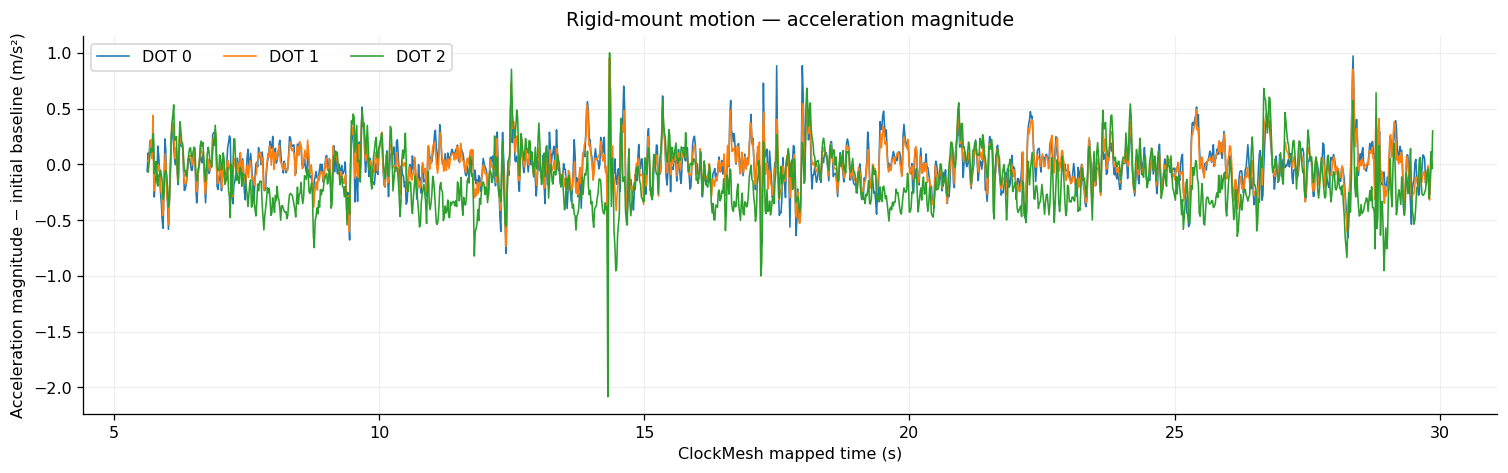

In [5]:
fig, ax = plt.subplots(figsize=(13, 4))
for sid, g in dot_official.groupby("sensor_id", sort=True):
    g = g.sort_values("t_mapped_s")
    first_s = g[g["t_mapped_s"] <= g["t_mapped_s"].min() + 1.0]["accel_mag_m_s2"]
    baseline = float(first_s.median()) if len(first_s) else float(g["accel_mag_m_s2"].median())
    ax.plot(g["t_mapped_s"], g["accel_mag_m_s2"] - baseline,
            label=f"DOT {sid}", color=colors(sid), lw=1.0)
ax.set(xlabel="ClockMesh mapped time (s)", ylabel="Acceleration magnitude − initial baseline (m/s²)",
       title="Rigid-mount motion — acceleration magnitude")
ax.legend(ncol=3)
plt.show()

## 5. Pairwise agreement between the rigidly mounted DOTs

To compare waveforms without adding timing corrections, interpolate each gyroscope magnitude onto the **same 60 Hz evaluation grid** over their shared mapped-time interval, then calculate Pearson correlations. Interpolation supports comparison on a grid; **no time offset is fitted or applied**. Strong correlation is evidence of relative motion alignment, not an absolute timing calibration.

,correlation_no_shift,sample_grid_points
pair,,
DOT 0 ↔ DOT 1,0.999848,1453
DOT 0 ↔ DOT 2,0.999220,1453
DOT 1 ↔ DOT 2,0.998852,1453


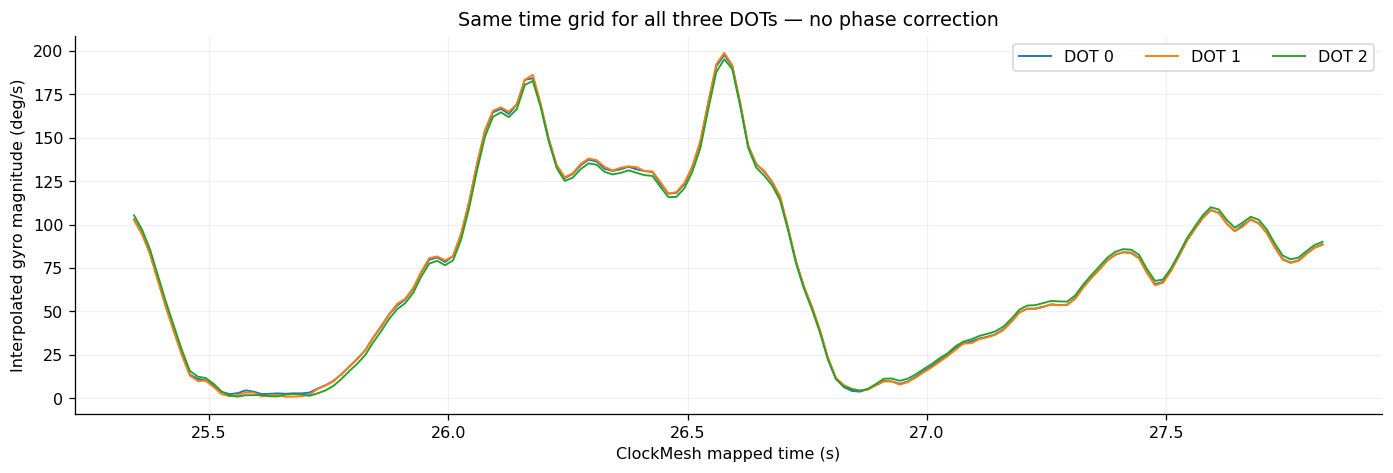

In [6]:
from itertools import combinations

series = {}
for sid, g in dot_official.groupby("sensor_id", sort=True):
    g = g.sort_values("t_mapped_s")
    series[int(sid)] = (g["t_mapped_s"].to_numpy(dtype=float), g["gyro_mag_deg_s"].to_numpy(dtype=float))
intersection_start = max(t[0] for t, _ in series.values())
intersection_end = min(t[-1] for t, _ in series.values())
common_grid = np.arange(intersection_start, intersection_end, 1/60)
assert len(common_grid) > 100
shared = {sid: np.interp(common_grid, t, value) for sid, (t, value) in series.items()}
agreement = []
for a, b in combinations(sorted(shared), 2):
    agreement.append({"pair": f"DOT {a} ↔ DOT {b}", "correlation_no_shift": np.corrcoef(shared[a], shared[b])[0, 1],
                      "sample_grid_points": len(common_grid)})
display(pd.DataFrame(agreement).set_index("pair").round(6))

fig, ax = plt.subplots(figsize=(12, 4))
for sid in sorted(shared):
    mask = (common_grid >= zoom[0]) & (common_grid <= zoom[1])
    ax.plot(common_grid[mask], shared[sid][mask], lw=1.2, label=f"DOT {sid}", color=colors(sid))
ax.set(xlabel="ClockMesh mapped time (s)", ylabel="Interpolated gyro magnitude (deg/s)",
       title="Same time grid for all three DOTs — no phase correction")
ax.legend(ncol=3)
plt.show()

## 6. Reference-clock mapping diagnostics

The first chart puts each accepted mapped time against the corresponding gateway callback time. The second plots the **pre-update gateway callback prediction error** (not physical synchronisation error). Each sensor has a separate ClockMesh model, but they use the same reference clock and origin.

For ECG, these diagnostics contain **one observation per BLE notification** (12.5 Hz), although `ecg_samples.csv` contains 16 individually mapped 200 Hz measurements for each packet.

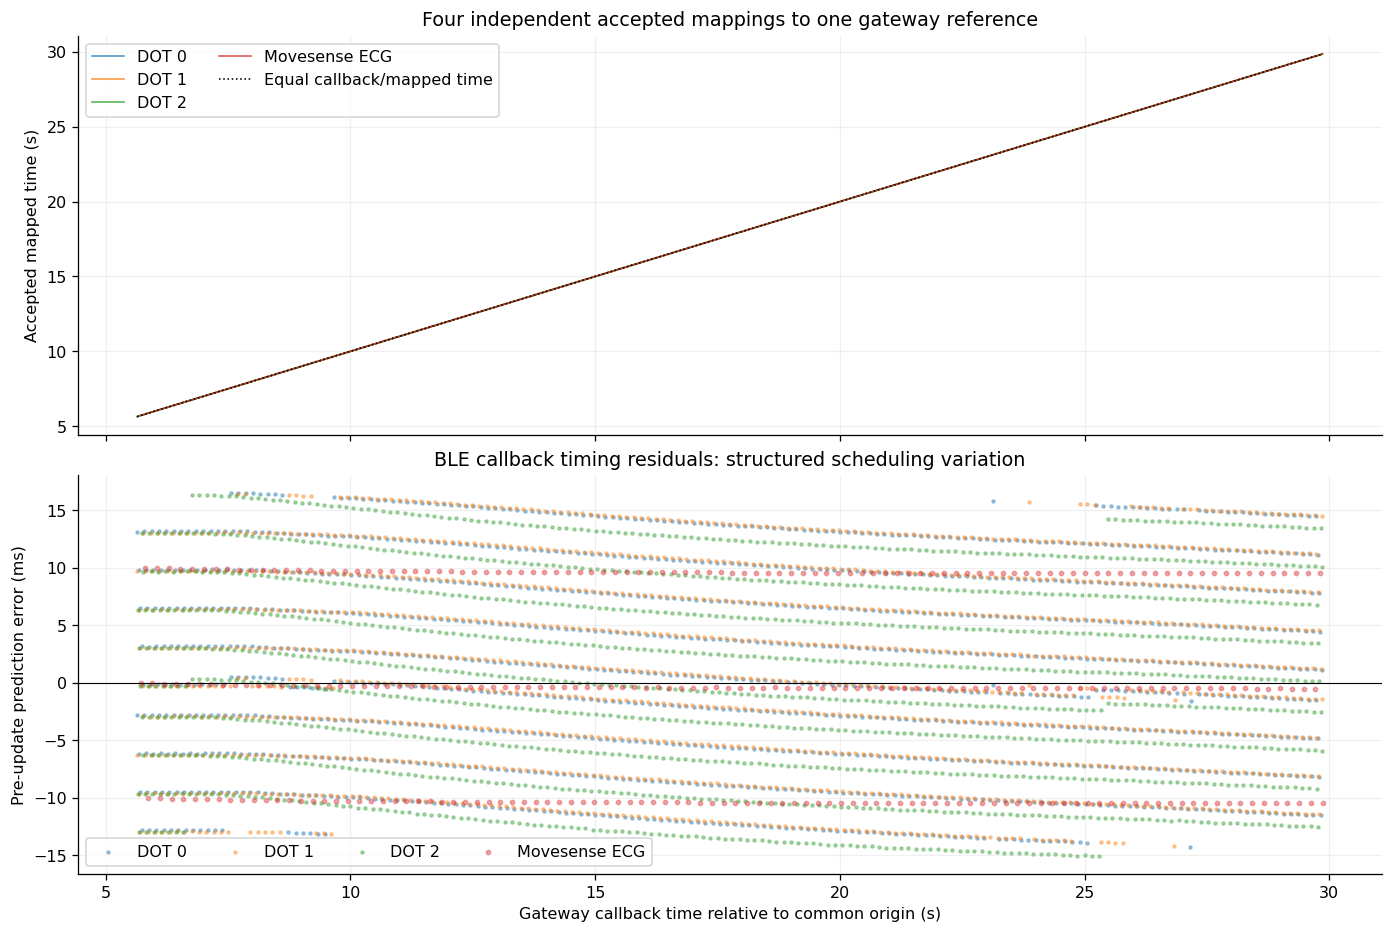

In [7]:
fig, (ax_map, ax_err) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
all_data = []
for sid, g in dot_official.groupby("sensor_id", sort=True):
    all_data.append((f"DOT {sid}", colors(sid), g))
all_data.append(("Movesense ECG", colors(3), pkt_official))

for name, color, g in all_data:
    ax_map.plot(g["t_callback_s"], g["t_mapped_s"], lw=1.0, alpha=.8, label=name, color=color)
    ax_err.scatter(g["t_callback_s"], g["latest_prediction_error_ns"].astype(float)/1e6,
                   s=7 if "Movesense" in name else 3.5, alpha=.38, color=color, label=name)
lo = min(g["t_callback_s"].min() for _, _, g in all_data)
hi = max(g["t_callback_s"].max() for _, _, g in all_data)
ax_map.plot([lo,hi],[lo,hi], color="black", ls=":", lw=1.0, label="Equal callback/mapped time")
ax_map.set(ylabel="Accepted mapped time (s)", title="Four independent accepted mappings to one gateway reference")
ax_map.legend(loc="upper left", ncol=2)
ax_err.axhline(0, color="black", lw=.7)
ax_err.set(xlabel="Gateway callback time relative to common origin (s)", ylabel="Pre-update prediction error (ms)",
           title="BLE callback timing residuals: structured scheduling variation")
ax_err.legend(ncol=4)
plt.show()

## 7. Accepted clock scale and mapping continuity

Each model estimates nanoseconds of gateway time per microsecond of sensor source time (nominally 1,000). During continuous tracking, ClockMesh may accept updated scale estimates while keeping the mapped timestamp of the current pivot unchanged. The full-affine acceptance at official start is intentionally different: it is allowed to correct the provisional mapping's offset.

Official-start full-affine acceptances: 4
Continuous-scale acceptances with exact pivot continuity: 4,665 / 4,665


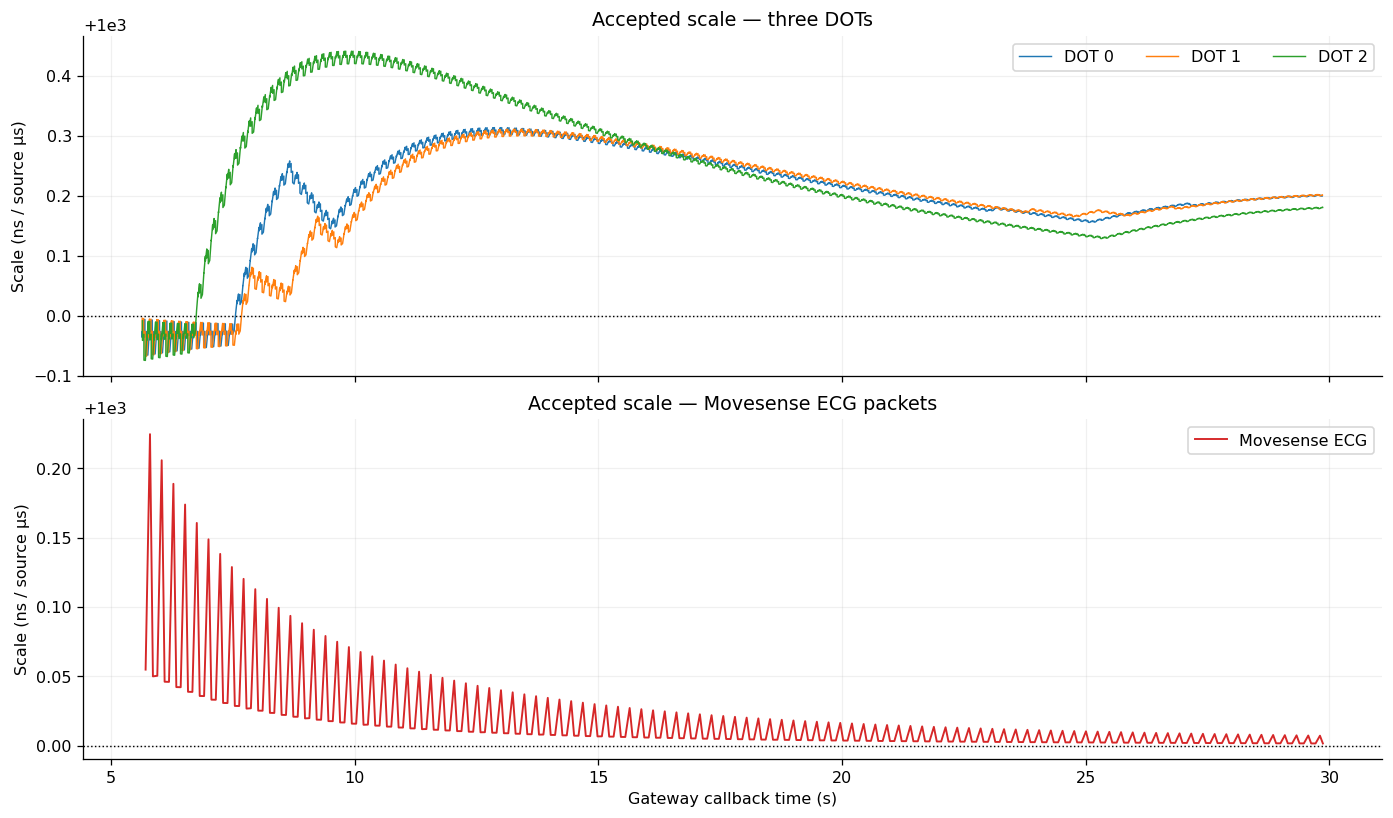

In [8]:
updates = pd.DataFrame(mapping_log["updates"])
full = updates[updates["kind"] == "official_start_full_affine"].copy()
cont = updates[updates["kind"] == "continuous_scale"].copy()
assert len(full) == 4, "Expected one full-affine acceptance for each sensor"
preserved = cont["mapped_pivot_before_ns"].eq(cont["mapped_pivot_after_ns"])
assert preserved.all(), "Some continuous-scale acceptances changed their pivot!"
print(f"Official-start full-affine acceptances: {len(full)}")
print(f"Continuous-scale acceptances with exact pivot continuity: {preserved.sum():,} / {len(cont):,}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for sid, g in dot_official.groupby("sensor_id", sort=True):
    axes[0].plot(g["t_callback_s"], g["estimated_scale_ns_per_source_unit"],
                 lw=.9, color=colors(sid), label=f"DOT {sid}")
axes[1].plot(pkt_official["t_callback_s"], pkt_official["estimated_scale_ns_per_source_unit"],
             lw=1.2, color=colors(3), label="Movesense ECG")
axes[0].axhline(1000, ls=":", color="black", lw=.9)
axes[1].axhline(1000, ls=":", color="black", lw=.9)
axes[0].set(ylabel="Scale (ns / source µs)", title="Accepted scale — three DOTs")
axes[1].set(xlabel="Gateway callback time (s)", ylabel="Scale (ns / source µs)", title="Accepted scale — Movesense ECG packets")
axes[0].legend(ncol=3)
axes[1].legend()
plt.show()

## 8. Validate ECG packet → sample mapping and boundary behaviour

The Movesense packet timestamp is interpreted as the **first sample** timestamp. Packet timing observations use the **last sample** as the ClockMesh observation anchor; individual samples are mapped at their own source time, 5 ms apart. This is essential: each packet must contribute **one** timing observation and **16** mapped ECG sample values.

One mapped-time decrease was reported at the **startup-to-official boundary**. Here we locate it in the CSV and distinguish it from monotonicity *within official measurement*. The first full-affine acceptance may correct offset; continuous scale acceptances must preserve pivot continuity.

Packets: 367 | ECG samples: 5872 | source sample interval: exactly 5 ms
Official ECG samples: 4848 | official mapped intervals all > 0: True
Mapped non-monotonic transitions across entire startup + measurement: 1


,stream_phase,packet_index,sample_index,mapped_diff_ns
1024,measurement,65,0,-765126.0


,packet_index,mapped_time_ns
event,,
Last mapped startup ECG sample,64,3977877702963
First official ECG sample,65,3977876937837


Mapped sample-to-sample transition: -0.765126 ms (source interval +5.000 ms)


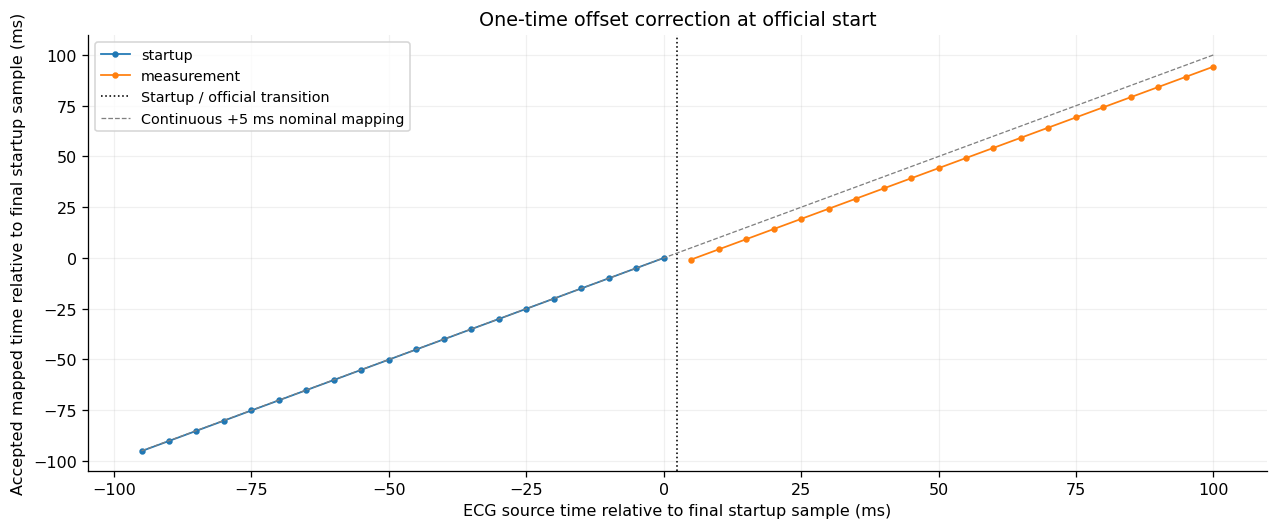

In [9]:
s = ecg_samples.copy().sort_values(["packet_index", "sample_index"]).reset_index(drop=True)
sp = ecg_packets.sort_values("packet_index").reset_index(drop=True)
source_step_us = s["source_sample_timestamp_us"].astype("int64").diff().dropna()
assert source_step_us.eq(5000).all()
assert sp["packet_sample_count"].eq(16).all()
assert len(s) == int(sp["packet_sample_count"].sum())
assert len(sp) == sp["model_observation_supplied"].eq(True).sum()

s["mapped_ns"] = pd.to_numeric(s["mapped_timestamp_ns"], errors="coerce")
s["mapped_diff_ns"] = s["mapped_ns"].diff()
non_monotonic = s[s["mapped_diff_ns"] <= 0]
official_steps = s.loc[s["stream_phase"] == "measurement", "mapped_ns"].diff().dropna()
assert (official_steps > 0).all(), "Non-monotonic ECG timing inside official measurement"
print(f"Packets: {len(sp)} | ECG samples: {len(s)} | source sample interval: exactly 5 ms")
print(f"Official ECG samples: {len(ecg_official)} | official mapped intervals all > 0: {bool((official_steps>0).all())}")
print(f"Mapped non-monotonic transitions across entire startup + measurement: {len(non_monotonic)}")
display(non_monotonic[["stream_phase", "packet_index", "sample_index", "mapped_diff_ns"]])

# Show the most recent mapped startup sample and the first official sample.
pre = s[(s["stream_phase"] == "startup") & s["mapped_ns"].notna()].tail(20).copy()
post = s[(s["stream_phase"] == "measurement") & s["mapped_ns"].notna()].head(20).copy()
if len(pre) and len(post):
    last_pre = pre.iloc[-1]
    first_post = post.iloc[0]
    offset = int(last_pre["mapped_ns"])
    boundary = pd.DataFrame([
        {"event": "Last mapped startup ECG sample", "packet_index": int(last_pre["packet_index"]),
         "mapped_time_ns": int(last_pre["mapped_ns"])},
        {"event": "First official ECG sample", "packet_index": int(first_post["packet_index"]),
         "mapped_time_ns": int(first_post["mapped_ns"])},
    ])
    display(boundary.set_index("event"))
    jump_ms = (float(first_post["mapped_ns"]) - float(last_pre["mapped_ns"])) / 1e6
    print(f"Mapped sample-to-sample transition: {jump_ms:+.6f} ms (source interval +5.000 ms)")
    around = pd.concat([pre, post]).copy()
    around["source_offset_ms"] = (around["source_sample_timestamp_us"].astype("int64") - int(last_pre["source_sample_timestamp_us"])) / 1000
    around["mapped_offset_ms"] = (around["mapped_ns"] - offset) / 1e6
    fig, ax = plt.subplots(figsize=(11, 4.5))
    for phase, g in around.groupby("stream_phase", sort=False):
        ax.plot(g["source_offset_ms"], g["mapped_offset_ms"], marker="o", lw=1.1, ms=3, label=phase)
    ax.axvline(2.5, color="black", lw=1, ls=":", label="Startup / official transition")
    ax.plot([around["source_offset_ms"].min(), around["source_offset_ms"].max()],
            [around["source_offset_ms"].min(), around["source_offset_ms"].max()],
            color="grey", lw=.8, ls="--", label="Continuous +5 ms nominal mapping")
    ax.set(xlabel="ECG source time relative to final startup sample (ms)",
           ylabel="Accepted mapped time relative to final startup sample (ms)",
           title="One-time offset correction at official start")
    ax.legend(loc="upper left", fontsize=9)
    plt.show()

## 9. Optional individual motion components

For rigidly mounted sensors, raw XYZ channels depend on mounting orientations. Magnitude is more appropriate for the initial alignment comparison. These component panels are available when inspecting an individual event or checking for a sensor-axis fault; each trace still uses `t_mapped_s`.

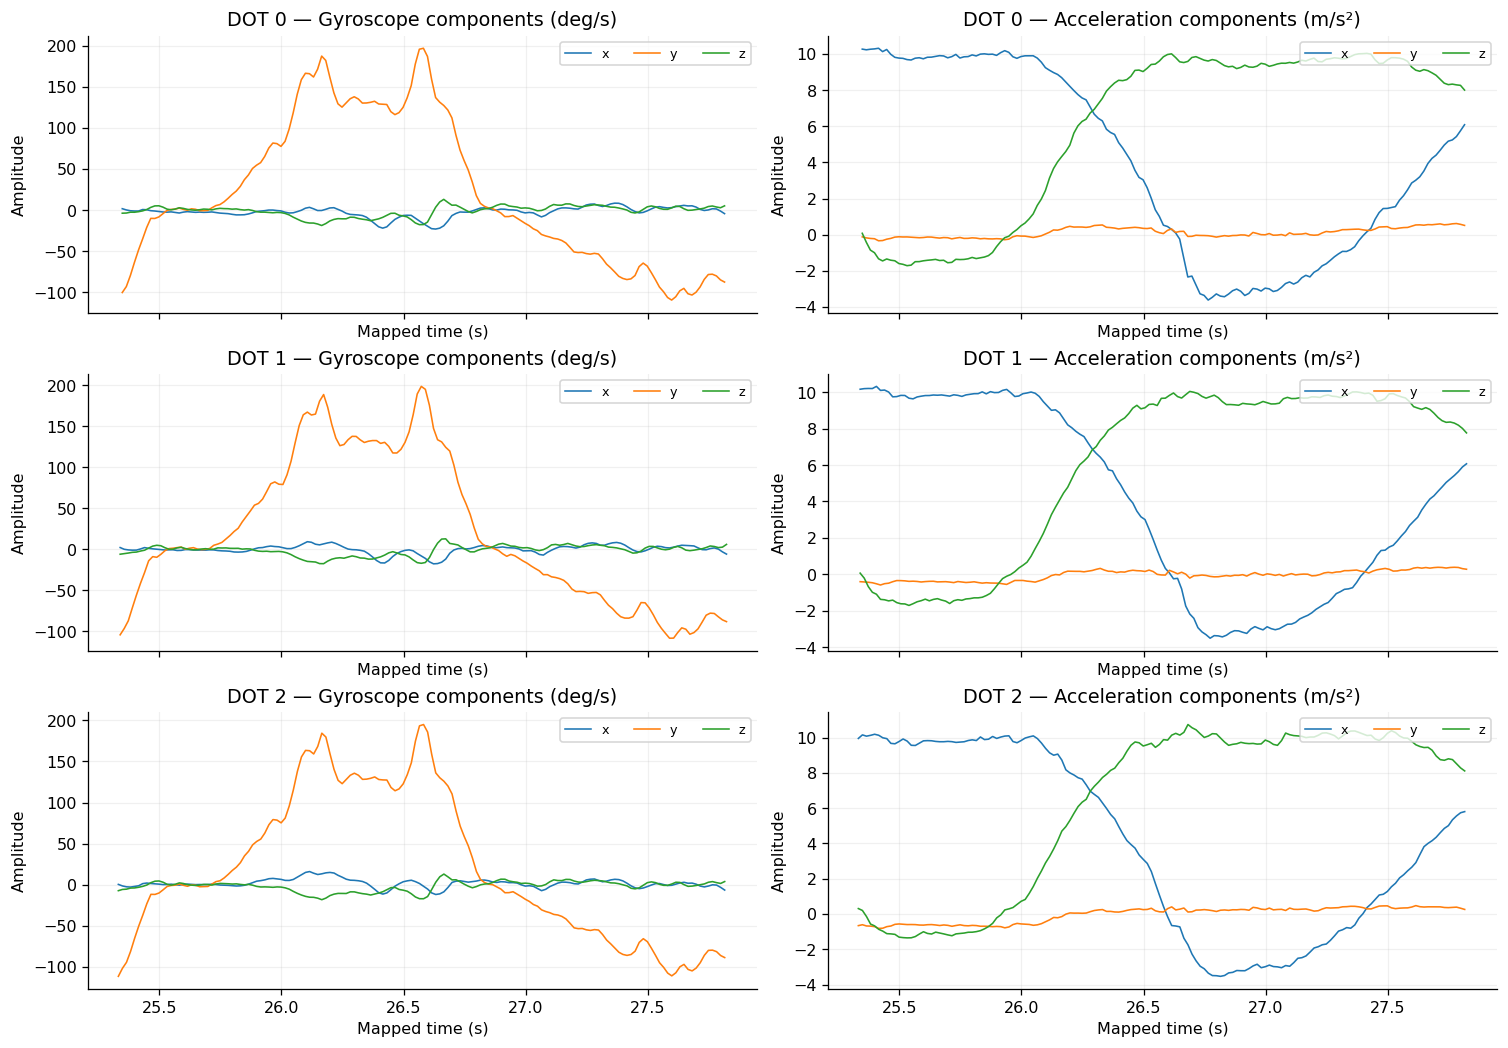

In [10]:
if SHOW_COMPONENTS:
    panels = [
        (["gyro_x_deg_s", "gyro_y_deg_s", "gyro_z_deg_s"], "Gyroscope components (deg/s)"),
        (["accel_x_m_s2", "accel_y_m_s2", "accel_z_m_s2"], "Acceleration components (m/s²)"),
    ]
    fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
    for row_index, (sid, g) in enumerate(dot_official.groupby("sensor_id", sort=True)):
        for col_index, (fields, title) in enumerate(panels):
            ax = axes[row_index, col_index]
            sample = g[g["t_mapped_s"].between(*zoom)]
            for field in fields:
                ax.plot(sample["t_mapped_s"], sample[field], lw=1.0, label=field.split("_")[1])
            ax.set(title=f"DOT {sid} — {title}", xlabel="Mapped time (s)", ylabel="Amplitude")
            ax.legend(ncol=3, loc="upper right", fontsize=8)
    plt.show()
else:
    print("Skipped individual DOT component plots (SHOW_COMPONENTS=False)")

## Conclusions and boundaries of this experiment

- Each of the three DOTs produces a 60 Hz motion stream. The Movesense produces 200 Hz ECG samples, packed into 16-sample BLE notifications. All **four independent ClockMesh models** reached the common official measurement phase.
- The **accepted mapped timeline**, not the callback time, is used for every sensor waveform in this notebook. Source timestamps and raw ECG amplitude values remain available for further analysis.
- Correlation between rigidly mounted DOTs can support a **relative motion alignment** claim. The chest-worn Movesense ECG signal does not provide a corresponding physical motion reference; mapping it alongside the DOTs demonstrates cross-sensor timeline infrastructure, not direct ECG/DOT offset accuracy.
- ECG sample source timestamps are regular at 5 ms. All official mapped ECG timestamps are monotonic. A **single discontinuity across the startup-to-official boundary** is expected under the policy that accepts a full scale-and-offset correction only once at official start; it should be labelled distinctly in diagnostics.
- During official tracking, every recorded continuous-scale acceptance preserves its mapped pivot. This is the continuity guarantee of the active mapping policy, **not a substitute for an independent timing reference**.
- For further precision tests, add a shared physical event measurable in both sensor modalities, or an externally referenced timing device. No event-based phase adjustment has been applied here.